# WattWise
## Predicting household appliance energy use with multiple linear regression
**Swayam Shakya** | Reproducible research project | October 2026

This notebook implements the proposed environmental regression study and tests whether calendar features and ridge regularization help. A separate extension evaluates rolling one-step forecasting. Results come from the public UCI measurements, not simulated training data.

**Run:** install `requirements.txt`, open this notebook from the extracted repository, and choose **Restart Kernel and Run All**. Keep the `src` and `data` folders beside it. No network is needed after installation because the original dataset is included.

**Version 2:** the original experiments are retained as reference. New searches and nested validation appear below. The original final period has already been inspected, so v2 results on that period are retrospective comparisons, not a newly untouched test.

## 1. Research design
**RQ1:** How well does multiple linear regression estimate appliance energy from recorded environmental conditions on a later period?
**RQ2:** Do cyclical calendar features, ridge regularization, or nonlinear modeling improve temporal generalization?
**RQ3 (separate task):** How does a rolling ten-minute forecast using only prior energy and calendar values compare with persistence?

The first 80% is development data; the final 20% is a locked chronological test period. Four expanding folds with a one-day gap select hyperparameters by RMSE. Preprocessing is fitted inside each fold. The test period is used for final evaluation and descriptive diagnostics, never for tuning. These are retrospective research estimates, not causal effects.

In [1]:
from pathlib import Path
import sys, os
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
ROOT = Path.cwd()
if not (ROOT / 'src/energy.py').exists():
    raise RuntimeError('Open this notebook from the WattWise repository folder.')
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.energy import (load_data, make_features, forecast_features, temporal_cv,
                        fit_experiments, rolling_forecast, diagnostics, make_plots)
pd.set_option('display.max_columns', 12)
SEED = 42

## 2. Provenance and validation
Candanedo (2017), *Appliances Energy Prediction*, UCI DOI: [10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G), CC BY 4.0. The data describe one Belgian dwelling; observations are not independent households. Appliance energy is **Wh per 10-minute interval**, not watts.

The loader rejects missing or non-finite values, negative energy, duplicate timestamps and interrupted cadence. No arbitrary spike removal or target imputation is performed. Weather interpolation limits real-time interpretation.

In [2]:
df = load_data()
cut = int(len(df) * 0.8)
train = df.iloc[:cut]
test = df.iloc[cut:]
display(pd.DataFrame({'rows':[len(train),len(test)],
                      'start':[train.date.min(), test.date.min()],
                      'end':[train.date.max(), test.date.max()]}, index=['development','test']))
print('Missing cells:', int(df.isna().sum().sum()))
print('Duplicate timestamps:', int(df.date.duplicated().sum()))
display(train[['Appliances','T1','RH_1','T_out']].describe())

Missing cells: 0
Duplicate timestamps: 0


,rows,start,end
development,15788,2016-01-11 17:00:00,2016-04-30 08:10:00
test,3947,2016-04-30 08:20:00,2016-05-27 18:00:00


,Appliances,T1,RH_1,T_out
count,15788.000000,15788.000000,15788.000000,15788.000000
mean,98.024449,21.152184,40.037455,5.855215
std,105.198291,1.214241,3.593212,4.129179
min,10.000000,16.790000,27.733333,-5.000000
25%,50.000000,20.500000,37.290000,2.950000
50%,60.000000,21.290000,39.530000,5.800000
75%,100.000000,22.000000,42.722708,8.800000
max,1080.000000,24.100000,63.360000,19.700000


## 3. Features and exclusions
The environmental model has 24 predictors: nine temperature/humidity pairs plus six weather variables. `T6`/`RH_6` are outside the building. Calendar models add sine/cosine hour and week encodings plus a weekend flag.

Exclude the target, raw timestamp, random controls `rv1`/`rv2`, and `lights`. Lighting is a simultaneous energy measurement; excluding it keeps the primary experiment focused on environmental and calendar predictors. No feature is selected using test correlations. Calendar cycles avoid a discontinuity between 23:50 and midnight.

In [3]:
X = make_features(df)
print('Predictors:', list(X.columns))
display(X.head())
print('Identical random controls:', np.array_equal(df.rv1, df.rv2))
display(train[['Appliances'] + list(X.columns[:8])].corr()['Appliances'].sort_values())

Predictors: ['T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour_sin', 'hour_cos', 'week_sin', 'week_cos', 'weekend']
Identical random controls: True


,T1,RH_1,T2,RH_2,T3,RH_3,...,Tdewpoint,hour_sin,hour_cos,week_sin,week_cos,weekend
0,19.89,47.596667,19.2,44.790000,19.79,44.730000,...,5.3,-0.965926,-0.258819,0.593820,0.804598,0
1,19.89,46.693333,19.2,44.722500,19.79,44.790000,...,5.2,-0.976296,-0.216440,0.598824,0.800881,0
2,19.89,46.300000,19.2,44.626667,19.79,44.933333,...,5.1,-0.984808,-0.173648,0.603804,0.797133,0
3,19.89,46.066667,19.2,44.590000,19.79,45.000000,...,5.0,-0.991445,-0.130526,0.608761,0.793353,0
4,19.89,46.333333,19.2,44.530000,19.79,45.000000,...,4.9,-0.996195,-0.087156,0.613695,0.789543,0


RH_2         -0.054834
RH_4          0.004894
RH_3          0.041958
T4            0.070492
T1            0.084496
RH_1          0.093932
T3            0.122718
T2            0.156221
Appliances    1.000000
Name: Appliances, dtype: float64

## 4. Model and evaluation mathematics
Multiple linear regression estimates $\hat y = \beta_0+\sum_j \beta_j x_j$ by minimizing squared errors. Ridge adds $\alpha\sum_j\beta_j^2$ after predictor standardization. Standardization uses training means and standard deviations only.

$MAE=\frac1n\sum_i|y_i-\hat y_i|$; $RMSE=\sqrt{\frac1n\sum_i(y_i-\hat y_i)^2}$; $R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$. MAE and RMSE are in Wh. Negative R² is possible. A model with lower RMSE can still have worse MAE.

Mean and median baselines, environmental MLR, calendar MLR, tuned ridge, and histogram gradient boosting are evaluated. Raw predictions are scored without clipping. Full implementation is in `src/energy.py`.

In [4]:
fold_rows = []
for fold, (tr, va) in enumerate(temporal_cv().split(train), 1):
    fold_rows.append({'fold':fold, 'train_rows':len(tr), 'validation_rows':len(va),
                      'train_end':train.date.iloc[tr[-1]],
                      'validation_start':train.date.iloc[va[0]]})
display(pd.DataFrame(fold_rows))

,fold,train_rows,validation_rows,train_end,validation_start
0,1,3016,3157,2016-02-01 15:30:00,2016-02-02 15:40:00
1,2,6173,3157,2016-02-23 13:40:00,2016-02-24 13:50:00
2,3,9330,3157,2016-03-16 11:50:00,2016-03-17 12:00:00
3,4,12487,3157,2016-04-07 10:00:00,2016-04-08 10:10:00


## 5. Run the primary experiments
This cell fits every candidate on the actual dataset, searches only within development data, saves fold scores, and refits each chosen configuration on the full development period. Boosting early stopping is disabled to avoid an internal random validation split. The reported CV score for a tuned model is a selection score, not an unbiased nested-CV estimate.

In [5]:
scores, predictions, fitted_models, manifest = fit_experiments(df)
display(scores.drop(columns='fit_seconds').round(4))
print('Model selected by CV:', manifest['selected_by_cv'])

Model selected by CV: Ridge calendar


,model,CV_RMSE_Wh,MAE_Wh,RMSE_Wh,R2,negative_predictions,parameters
0,Mean baseline,99.8896,52.6849,91.0534,-0.0003,0,{}
1,Median baseline,107.8526,43.2784,98.0372,-0.1597,0,{}
2,MLR environment,101.3955,51.1555,86.5087,0.0970,43,{}
3,MLR calendar,100.5980,46.9333,85.6858,0.1141,48,{}
4,Ridge calendar,93.6013,47.2218,84.7076,0.1342,3,"{""ridge__alpha"": 1000.0}"
5,Gradient boosting,102.7170,97.8292,125.8777,-0.9118,0,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 7}"


## 6. Training exploration and held-out visual diagnostics
The histogram, hourly profile and feature correlations use development data only. The timeline includes the full series as a retrospective description. The held-out prediction plot shows the first 48 hours by a fixed rule, rather than choosing a favorable window.

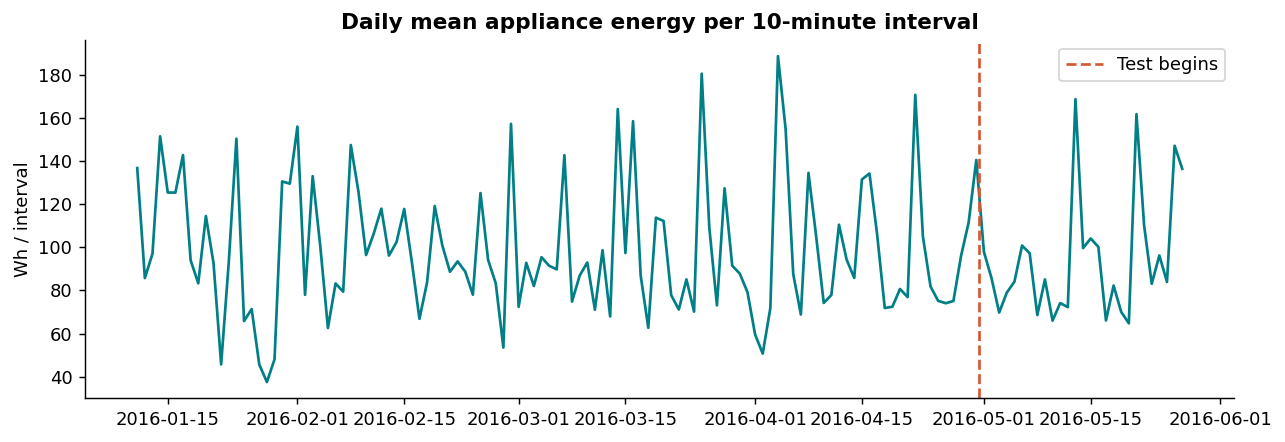

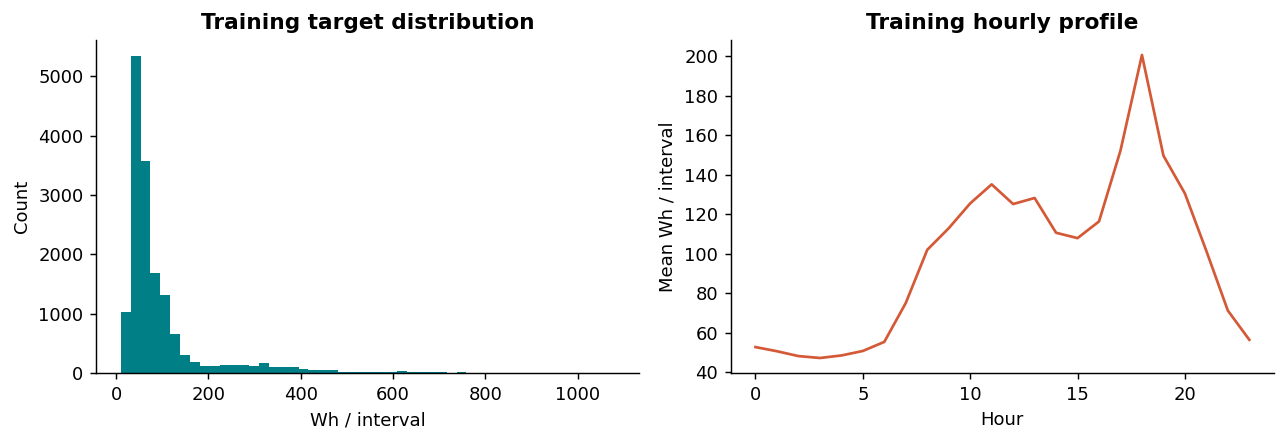

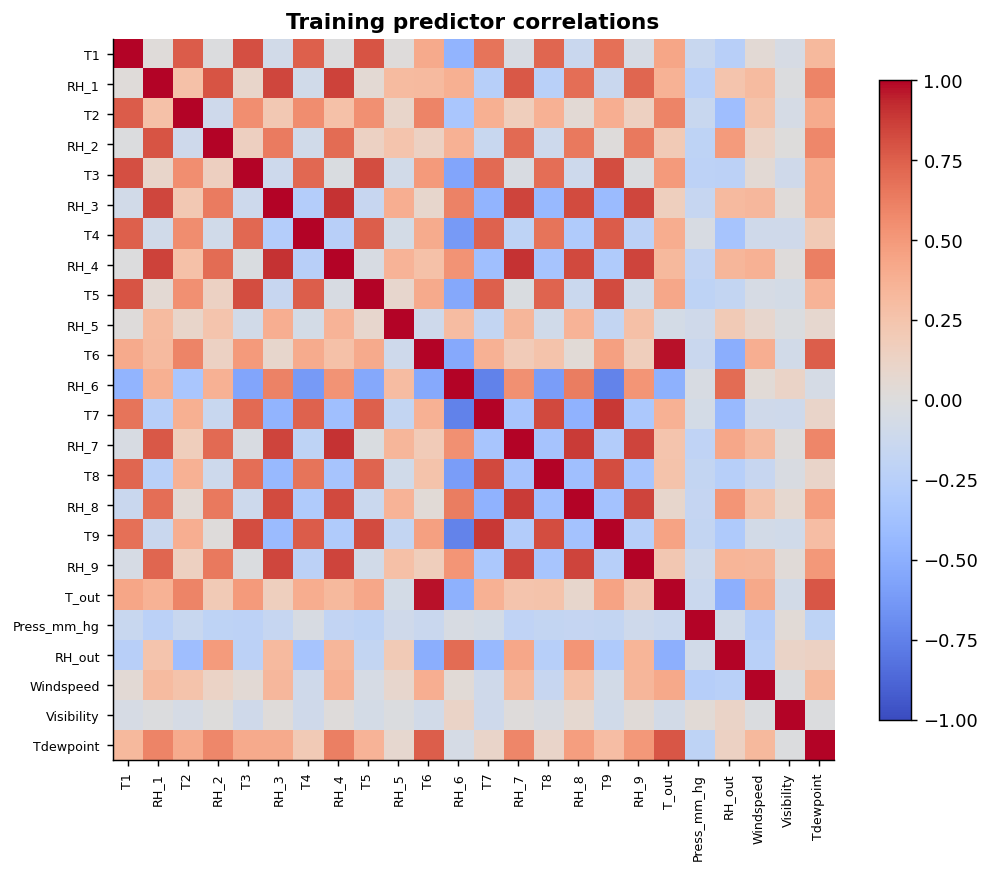

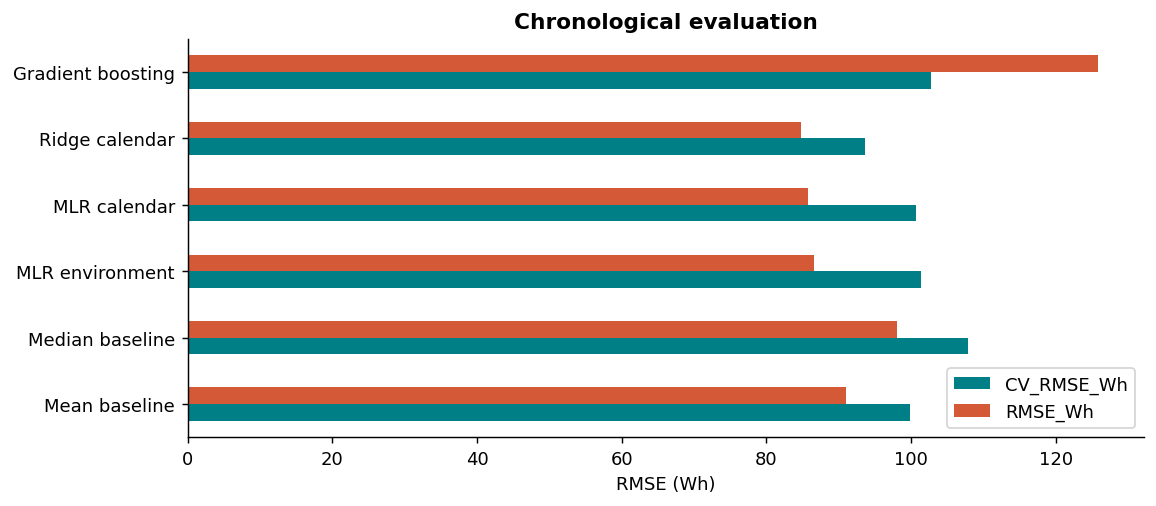

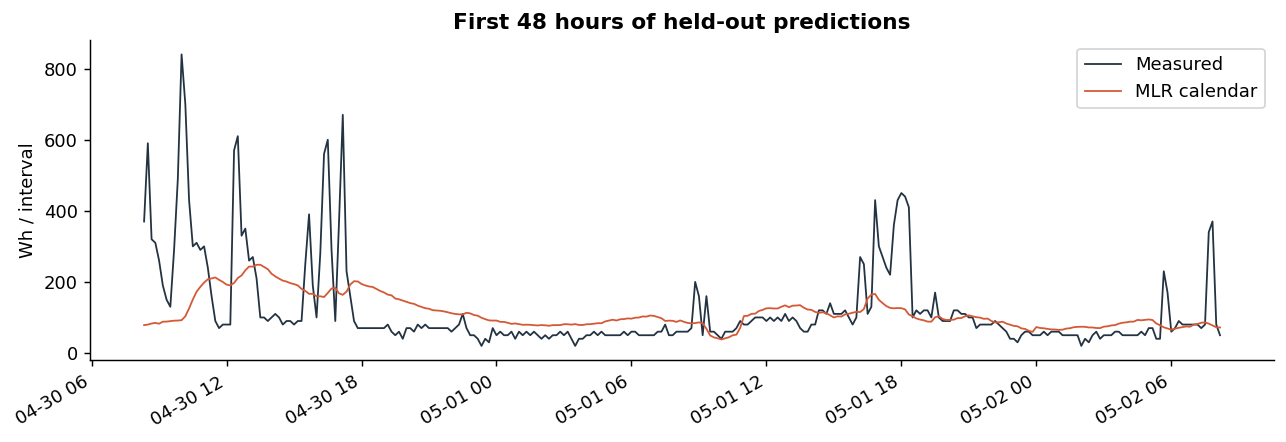

In [6]:
make_plots(df, scores, predictions, manifest)
for name in ['timeline','eda','correlations','comparison','predictions']:
    display(Image(filename=str(ROOT / 'results/figures' / f'{name}.png')))

## 7. Interpretability and uncertainty
Standardized coefficients describe changes in predicted Wh per training standard deviation, conditional on other predictors. They are not causal effects. Variance inflation factors reveal redundant predictor information. Residual dependence and peak-demand errors help explain where MLR fails.

A paired circular block bootstrap resamples contiguous 144-row blocks 1,000 times to estimate an exploratory interval for the MLR-minus-mean RMSE difference. It is conditional on the fitted models and this test window; it does not quantify retraining uncertainty or guarantee performance in another dwelling.

MLR_residual_lag1_correlation                                             0.691244
training_peak_threshold_Wh                                                   210.0
MLR_peak_MAE_Wh                                                         225.727008
MLR_nonpeak_MAE_Wh                                                       30.890193
test_peak_count                                                                325
condition_number_scaled_design                                           62.825662
MLR_calendar_minus_mean_RMSE_CI_95_Wh    [-8.666462569303132, -1.7417330161178532]
bootstrap_block_rows                                                           144
bootstrap_repeats                                                             1000
dtype: object

,feature,coefficient_Wh_per_training_SD
3,RH_2,-38.042128
16,T9,-35.254859
2,T2,-31.738214
25,hour_cos,-27.547357
24,hour_sin,-17.335428
15,RH_8,-16.866056
17,RH_9,-8.701428
13,RH_7,-8.448306
11,RH_6,-8.325472
26,week_sin,-7.634564


,feature,VIF
18,T_out,237.735764
23,Tdewpoint,166.264449
20,RH_out,79.996243
10,T6,31.018618
16,T9,17.927579
2,T2,17.421371
7,RH_4,17.151193
3,RH_2,16.746877
0,T1,14.772876
1,RH_1,13.644867


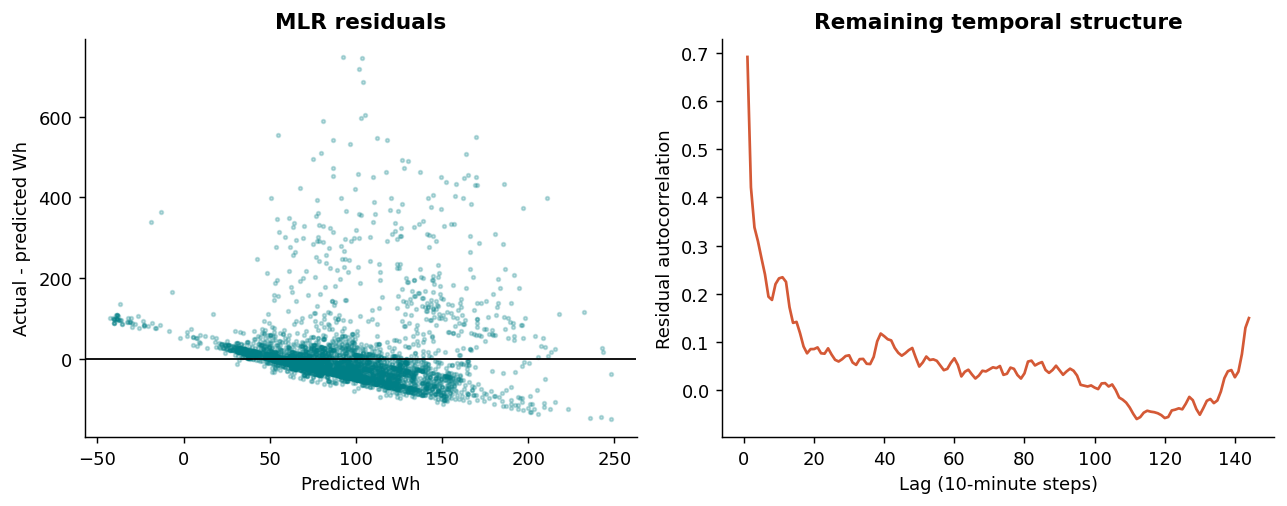

In [7]:
diagnostic_summary = diagnostics(df, predictions, fitted_models, manifest)
display(pd.Series(diagnostic_summary))
display(pd.read_csv(ROOT/'results/coefficients.csv').sort_values('coefficient_Wh_per_training_SD'))
display(pd.read_csv(ROOT/'results/vif.csv').sort_values('VIF',ascending=False).head(10))
display(Image(filename=str(ROOT/'results/figures/residuals.png')))

## 8. Separate rolling one-step forecast
At target interval t, use energy from t-1, t-6, t-144 and the mean of t-6 through t-1, plus the known calendar. No contemporaneous environmental measurements enter this model. The first 144 rows are unavailable due to lag construction.

Earlier test targets are allowed only after they would have been observed, as in an online one-step forecast. The fitted coefficients remain fixed. This is **not** a single-origin forecast of the entire test month. Persistence predicts the last observed value; the seasonal baseline predicts the value one day earlier.

In [8]:
lag_features = forecast_features(df)
forecast_scores, forecast_predictions = rolling_forecast(df)
display(lag_features.iloc[144:149])
display(forecast_scores.round(4))

,hour_sin,hour_cos,week_sin,week_cos,weekend,lag_1,lag_6,lag_144,past_hour_mean
144,-0.965926,-0.258819,0.999301,0.037391,0,40.0,30.0,60.0,40.000000
145,-0.976296,-0.216440,0.999514,0.031162,0,60.0,40.0,60.0,45.000000
146,-0.984808,-0.173648,0.999689,0.024931,0,60.0,50.0,50.0,48.333333
147,-0.991445,-0.130526,0.999825,0.018699,0,210.0,40.0,50.0,75.000000
148,-0.996195,-0.087156,0.999922,0.012466,0,380.0,40.0,60.0,131.666667


,model,MAE_Wh,RMSE_Wh,R2,negative_predictions
0,Persistence,26.6506,66.4376,0.4674,0
1,Previous day,53.6787,112.1771,-0.5183,0
2,Lagged ridge,26.8965,60.9941,0.5511,0


## 9. Estimate energy for example conditions
The small command-line interface refits the fixed ridge recipe on development data. It returns raw and nonnegative estimates separately and flags values outside training predictor ranges. Clipped estimates are a convenience output and are not the benchmark scores. The example contains real held-out conditions; it is not evidence of external validation.

In [9]:
from predict import predict_csv
display(predict_csv(ROOT/'data/example_conditions.csv', ROOT/'results/example_predictions.csv'))

,date,prediction_raw_Wh,prediction_nonnegative_Wh,outside_training_range,model
0,2016-05-27 17:40:00,135.837255,135.837255,True,Ridge calendar (v1 reference)
1,2016-05-27 17:50:00,132.446331,132.446331,True,Ridge calendar (v1 reference)
2,2016-05-27 18:00:00,129.343222,129.343222,True,Ridge calendar (v1 reference)


## Initial-study interpretation and references
The environmental regression question and the lagged forecasting question must be interpreted separately. Weak environmental generalization is a meaningful finding: environmental measurements alone do not capture all appliance switching behavior. More complex models do not necessarily transfer better across time. A single dwelling and partial-year coverage prevent population-level conclusions.

The paper and report discuss actual scores, negative predictions, collinearity, residual dependence, the bootstrap assumptions and future validation. This project is a reproducible empirical study, not a claim of a new algorithm or publication acceptance.

## References
1. Candanedo, L. (2017). Appliances Energy Prediction [Dataset]. UCI. https://doi.org/10.24432/C5VC8G
2. Candanedo, L. M., Feldheim, V., & Deramaix, D. (2017). Data driven prediction models of energy use of appliances in a low-energy house. *Energy and Buildings, 140*, 81-97. https://doi.org/10.1016/j.enbuild.2017.01.083
3. Original research repository: https://github.com/LuisM78/Appliances-energy-prediction-data
4. scikit-learn, LinearRegression documentation: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
5. scikit-learn, TimeSeriesSplit documentation: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html

## 10. Version 2: bounded model improvement
Three real defects were reproduced and fixed: empty-data acceptance, incorrect source-hash tracking for alternative files, and forecasting dependence on row labels.

We now compare 13 environmental configurations and 17 forecasting configurations. The model family and parameters are selected using only the development period. Three outer chronological folds each repeat the entire selection process using three inner folds with a one-day gap. Final selection uses four folds on the full development period. Nested scores evaluate the selection procedure, not just the final winning recipe.

Environmental alternatives include broader ridge penalties, additive splines and extra trees. Forecast alternatives use additional lags, past-window variability and nonlinear models. All window statistics are shifted before aggregation. No feature uses the current or future target.

This cell trains every configuration and repeats nested validation. Allow several minutes. The original holdout was inspected in version 1; subsequent results are exploratory. The default environmental interface retains the original ridge recipe; the v2 tree alternative is explicitly experimental.

environment: final CV selected Extra trees, RMSE=92.252
environment nested fold 1: Ridge expanded, RMSE=96.510
environment nested fold 2: Extra trees, RMSE=89.897
environment nested fold 3: Extra trees, RMSE=92.643
forecast: final CV selected History extra trees, RMSE=63.007
forecast nested fold 1: History extra trees, RMSE=66.618
forecast nested fold 2: History extra trees, RMSE=61.331
forecast nested fold 3: History extra trees, RMSE=60.925

environment retrospective holdout:
           model  CV_RMSE_Wh    MAE_Wh   RMSE_Wh        R2  negative_predictions  selected_by_CV                                                parameters
   Mean baseline   99.889589 52.684938 91.053435 -0.000327                     0           False                                                        {}
 Median baseline  107.852611 43.278439 98.037236 -0.159663                     0           False                                                        {}
    MLR calendar  100.597973 46.933255 85.685781  0.

,model,CV_RMSE_Wh,MAE_Wh,RMSE_Wh,R2,negative_predictions,selected_by_CV,parameters
0,Mean baseline,99.8896,52.6849,91.0534,-0.0003,0,False,{}
1,Median baseline,107.8526,43.2784,98.0372,-0.1597,0,False,{}
2,MLR calendar,100.5980,46.9333,85.6858,0.1141,48,False,{}
3,Ridge expanded,93.6013,47.2218,84.7076,0.1342,3,False,"{""ridge__alpha"": 1000.0}"
4,Additive splines,97.4257,64.6441,91.6125,-0.0126,0,False,"{""ridge__alpha"": 1000.0, ""splinetransformer__n..."
5,Extra trees,92.2523,61.3649,91.1867,-0.0033,0,True,"{""min_samples_leaf"": 60}"


,model,CV_RMSE_Wh,MAE_Wh,RMSE_Wh,R2,negative_predictions,selected_by_CV,parameters
0,Mean baseline,99.9727,52.6586,91.0524,-0.0003,0,False,{}
1,Median baseline,107.9117,43.2784,98.0372,-0.1597,0,False,{}
2,Persistence,72.0634,26.6506,66.4376,0.4674,0,False,{}
3,History ridge,65.5912,27.6592,59.6947,0.5700,0,False,"{""ridge__alpha"": 1000.0}"
4,History boosting,63.5801,25.3067,58.0010,0.5941,0,False,"{""l2_regularization"": 100.0, ""loss"": ""squared_..."
5,History extra trees,63.0075,25.5056,57.2297,0.6048,0,True,"{""min_samples_leaf"": 5}"


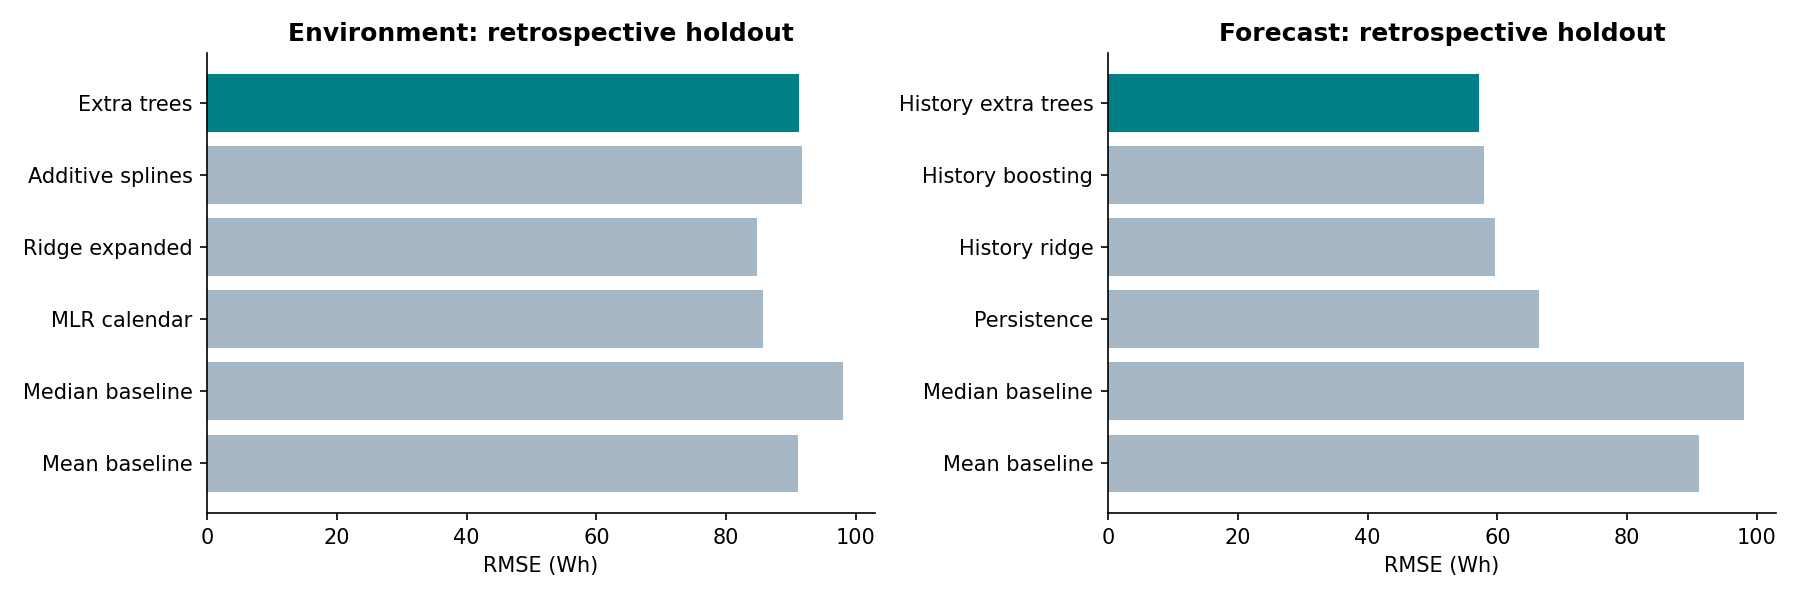

In [10]:
from src.enhanced import run_enhancements
enhanced_scores = run_enhancements(df)
for task, table in enhanced_scores.items():
    print(task)
    display(table.round(4))
display(Image(filename=str(ROOT/'results/enhanced/comparison.png')))

## 11. Nested validation and uncertainty sensitivity
Each outer validation interval follows its training interval and is excluded from the inner search. The forecast is still rolling one-step: earlier measurements in a validation period can be used only after they would have become observable. Scores across outer folds refer to potentially different selected models.

Paired block-bootstrap intervals at 6-hour, 24-hour and 48-hour block lengths show sensitivity to the dependence assumption. These intervals are conditional on fitted models and the inspected period; they do not remove selection bias or substitute for external validation.

In [11]:
import json
for task in ['environment','forecast']:
    print(task)
    display(pd.read_csv(ROOT/f'results/enhanced/{task}_nested.csv'))
    print((ROOT/f'results/enhanced/{task}_uncertainty.json').read_text())

environment
{
  "comparison": "Extra trees minus Mean baseline",
  "interpretation": "Exploratory paired RMSE difference, conditional on fitted models; not selection-adjusted",
  "intervals_95_percent": [
    {
      "block_rows": 36,
      "low_Wh": -6.608764728374679,
      "high_Wh": 8.34170551024278
    },
    {
      "block_rows": 144,
      "low_Wh": -7.874301675422819,
      "high_Wh": 9.146689194373183
    },
    {
      "block_rows": 288,
      "low_Wh": -8.713607956976864,
      "high_Wh": 10.412207664895046
    }
  ]
}
forecast
{
  "comparison": "History extra trees minus Persistence",
  "interpretation": "Exploratory paired RMSE difference, conditional on fitted models; not selection-adjusted",
  "intervals_95_percent": [
    {
      "block_rows": 36,
      "low_Wh": -11.60093289322637,
      "high_Wh": -6.800245394914982
    },
    {
      "block_rows": 144,
      "low_Wh": -11.348777435470426,
      "high_Wh": -6.882545774392813
    },
    {
      "block_rows": 288,
     

,fold,selected_model,parameters,train_end,validation_start,validation_end,...,MAE_Wh,RMSE_Wh,R2,negative_predictions,baseline_RMSE_Wh,seconds
0,1,Ridge expanded,"{""ridge__alpha"": 10000.0}",2016-02-07 02:40:00,2016-02-08 02:50:00,2016-03-06 12:30:00,...,63.860345,96.510371,0.053535,0,99.202467,1.833599
1,2,Extra trees,"{""min_samples_leaf"": 60}",2016-03-05 12:30:00,2016-03-06 12:40:00,2016-04-02 22:20:00,...,50.979813,89.896756,0.186213,0,99.658294,3.948227
2,3,Extra trees,"{""min_samples_leaf"": 60}",2016-04-01 22:20:00,2016-04-02 22:30:00,2016-04-30 08:10:00,...,51.086170,92.643082,0.194100,0,103.216648,6.423420


,fold,selected_model,parameters,train_end,validation_start,validation_end,...,MAE_Wh,RMSE_Wh,R2,negative_predictions,baseline_RMSE_Wh,seconds
0,1,History extra trees,"{""min_samples_leaf"": 5}",2016-02-07 20:40:00,2016-02-08 20:50:00,2016-03-07 00:30:00,...,32.482230,66.617905,0.519652,0,72.361101,6.065170
1,2,History extra trees,"{""min_samples_leaf"": 20}",2016-03-06 00:30:00,2016-03-07 00:40:00,2016-04-03 04:20:00,...,27.842769,61.330654,0.615021,0,70.863289,9.794538
2,3,History extra trees,"{""min_samples_leaf"": 5}",2016-04-02 04:20:00,2016-04-03 04:30:00,2016-04-30 08:10:00,...,27.118616,60.925361,0.654041,0,72.279430,16.458513


## 12. A real next-interval forecasting interface
Supply at least 144 consecutive measured readings in a CSV with `date` and `Appliances`. The interface derives the next timestamp and uses only historical values. It refits the selected recipe on development data and does not serialize or load pickle models. The example is drawn from real held-out measurements.

`python forecast.py data/example_history.csv results/next_interval.csv`

The environmental interface remains `python predict.py ...`; opt into its experimental v2 recipe only with `--experimental-v2`.

In [12]:
from forecast import forecast_csv
display(forecast_csv(ROOT/'data/example_history.csv',ROOT/'results/next_interval.csv'))

,date,prediction_raw_Wh,prediction_nonnegative_Wh,model
0,2016-05-27 18:00:00,315.255224,315.255224,History extra trees


## 13. Full verification
The suite tests real-data training, CSV interfaces, independently recomputed scores, nested boundaries, future-target invariance, input validation and the three reproduced defects. JUnit XML and captured logs are saved as evidence. Numerical fixtures only test arithmetic; they are never used as research training data.

In [13]:
import subprocess
completed = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--junitxml=results/test_results.xml'], cwd=ROOT, capture_output=True, text=True)
(ROOT/'results/test_run.log').write_text(completed.stdout + completed.stderr)
print(completed.stdout)
if completed.returncode:
    print(completed.stderr)
    raise RuntimeError('Project tests failed')

.................................................                        [100%]
49 passed in 22.15s

